# Customer Churn Prediction — Supervised Learning Set B
Dataset: IBM Telco Customer Churn

## Project goal
Predict whether a telecom customer will leave (`Churn = Yes`). The notebook follows the practical exam's Steps 1–8. Run cells from top to bottom.



## Step 1 — Problem framing & theory notes

### 1. What is customer churn and why does it matter?
- **Churn** means a customer stops using the company's service.
- Finding likely churners early lets a retention team offer relevant support or plans before the customer leaves.
- Acquiring a new customer costs money (**CAC: Customer Acquisition Cost**); retaining a customer can protect their future value (**CLV: Customer Lifetime Value**).

### 2. Confusion matrix
- **TP:** model predicts churn and the customer really churns.
- **TN:** model predicts no churn and the customer really stays.
- **FP:** model flags a customer who would have stayed; this can waste a retention call or offer.
- **FN:** model misses a customer who actually leaves; the company loses a chance to retain them. This is especially costly in this exam scenario.

### 3. Class imbalance and SMOTE
- Class imbalance means one target class appears much more often than the other.
- This dataset has fewer churners than non-churners, so accuracy alone can hide poor churn detection.
- SMOTE creates synthetic minority-class examples from training samples. It must be fitted only on training data, never on the test set.

### 4. Four algorithms
- **KNN:** predicts using the labels of nearby training examples. Scaling matters because it uses distances.
- **Gaussian Naive Bayes:** uses Bayes' theorem and assumes features are conditionally independent within each class.
- **SVM:** finds a separating boundary; an RBF kernel can model nonlinear boundaries. Scaling matters.
- **Decision Tree:** learns a sequence of feature-based splits and is relatively easy to explain.

### 5. Precision versus recall
- Precision is useful when unnecessary retention calls or discounts are very costly.
- Recall is the priority here because a false negative means missing a real churner. The best operational choice should still consider the number of customers the team can contact.

## Step 2 — Load and inspect the data

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings("ignore")

DATA_PATH = "C://Users//Asus//Mahesh_Program//Machine_Learning_Superviced_learniing//telco-churn-supervised-learning//Telco-Customer-Churn.csv"
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
display(df.head(10))
df.info()
display(df.describe(include="all").T)

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# TotalCharges is text in the source file because some rows contain blank strings.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].astype(str).str.strip(), errors="coerce")
print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).head(10))
print("\\nTarget counts:")
display(df["Churn"].value_counts())
print("\\nTarget percentages:")
display((df["Churn"].value_counts(normalize=True) * 100).round(2))

Missing values by column:


TotalCharges      11
gender             0
SeniorCitizen      0
Partner            0
customerID         0
Dependents         0
tenure             0
MultipleLines      0
PhoneService       0
OnlineSecurity     0
dtype: int64

\nTarget counts:


Churn
No     5174
Yes    1869
Name: count, dtype: int64

\nTarget percentages:


Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

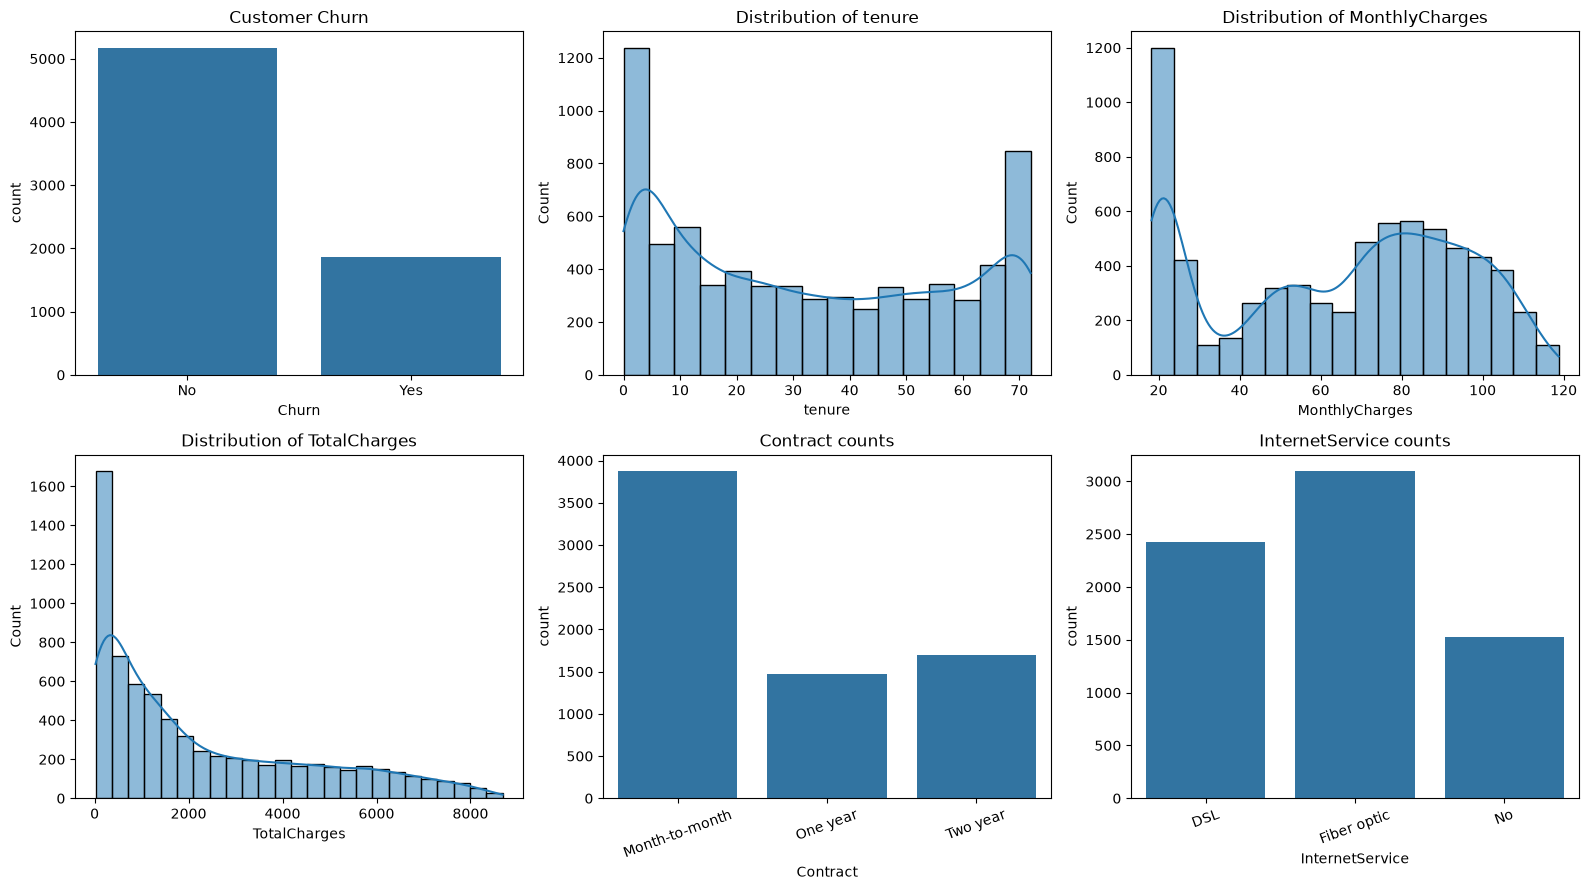

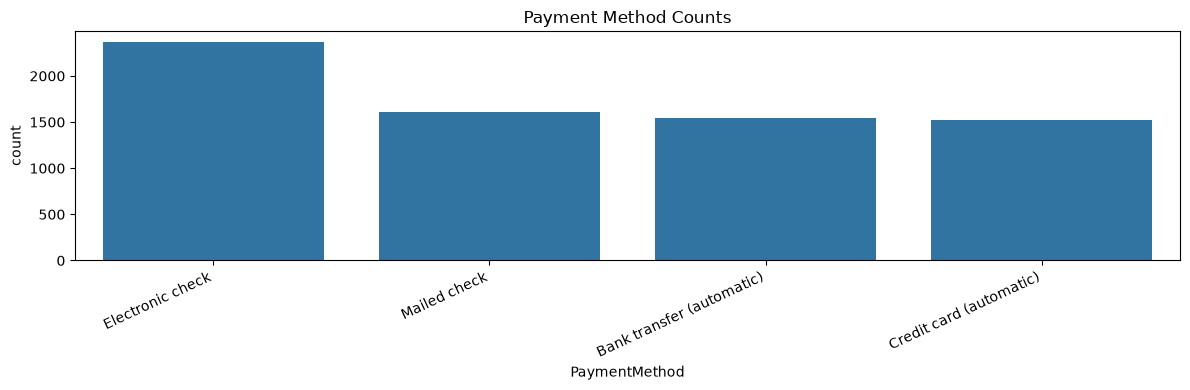

In [6]:
# Univariate charts
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
sns.countplot(data=df, x="Churn", ax=axes[0, 0])
axes[0, 0].set_title("Customer Churn")
for ax, col in zip(axes[0, 1:], ["tenure", "MonthlyCharges"]):
    sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
sns.histplot(data=df, x="TotalCharges", kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Distribution of TotalCharges")
for ax, col in zip(axes[1, 1:], ["Contract", "InternetService"]):
    sns.countplot(data=df, x=col, ax=ax)
    ax.tick_params(axis="x", rotation=20)
    ax.set_title(f"{col} counts")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
sns.countplot(data=df, x="PaymentMethod")
plt.xticks(rotation=25, ha="right")
plt.title("Payment Method Counts")
plt.tight_layout()
plt.show()

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn rate (%), dtype: float64

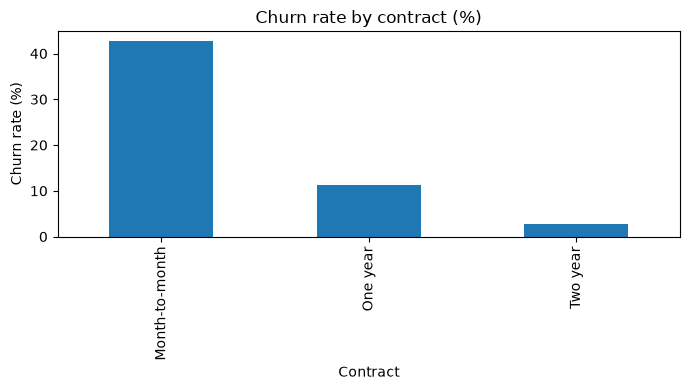

tenure_bucket
0–12     47.438243
13–24    28.710938
25–48    20.388959
49–72     9.513176
Name: Churn rate (%), dtype: float64

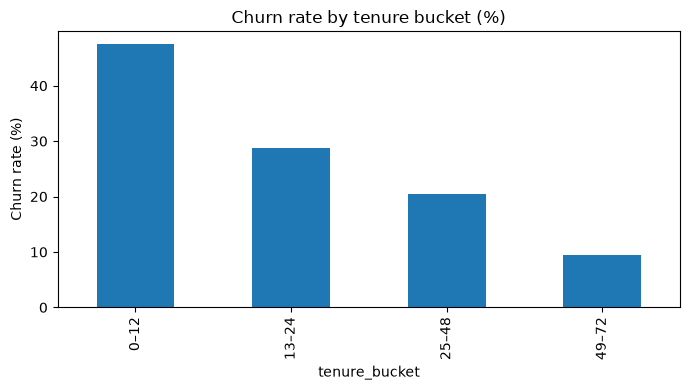

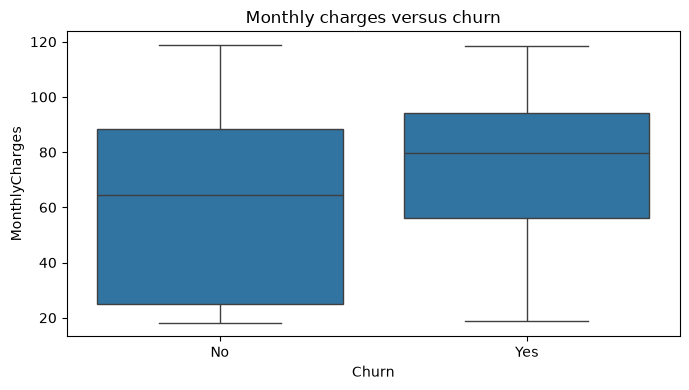

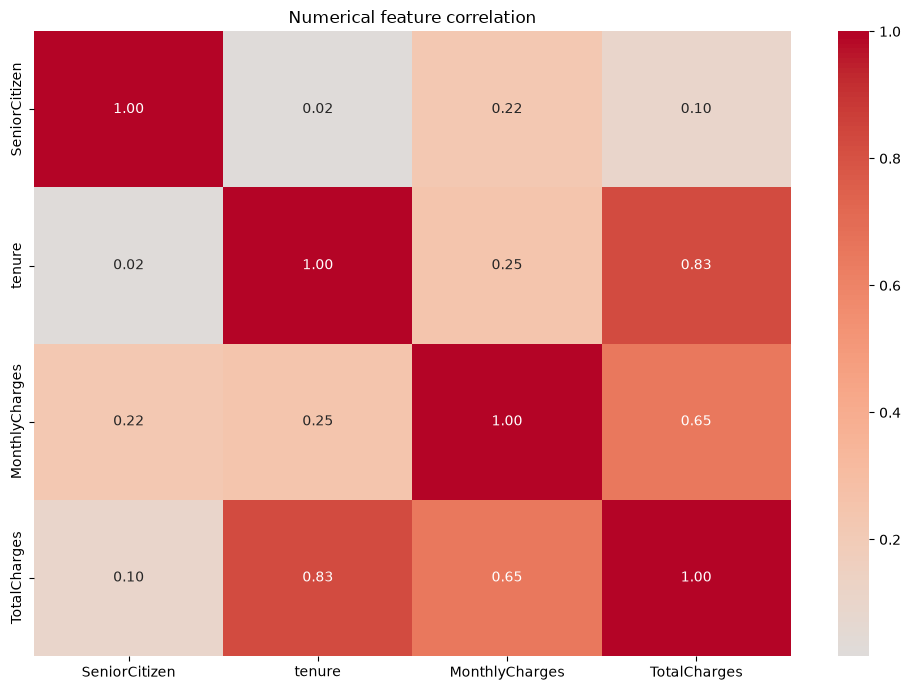

In [7]:
# Bivariate analysis
contract_rate = pd.crosstab(df["Contract"], df["Churn"], normalize="index")["Yes"] * 100
display(contract_rate.rename("Churn rate (%)").sort_values(ascending=False))
contract_rate.sort_values(ascending=False).plot(kind="bar", figsize=(7, 4), title="Churn rate by contract (%)")
plt.ylabel("Churn rate (%)")
plt.tight_layout()
plt.show()

df["tenure_bucket"] = pd.cut(
    df["tenure"], bins=[-1, 12, 24, 48, 72],
    labels=["0–12", "13–24", "25–48", "49–72"]
)
bucket_rate = pd.crosstab(df["tenure_bucket"], df["Churn"], normalize="index")["Yes"] * 100
display(bucket_rate.rename("Churn rate (%)"))
bucket_rate.plot(kind="bar", figsize=(7, 4), title="Churn rate by tenure bucket (%)")
plt.ylabel("Churn rate (%)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly charges versus churn")
plt.tight_layout()
plt.show()

numeric = df.select_dtypes(include=np.number)
plt.figure(figsize=(10, 7))
sns.heatmap(numeric.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Numerical feature correlation")
plt.tight_layout()
plt.show()

## Step 3 — Cleaning, feature engineering, encoding, scaling and split

The notebook uses a preprocessing pipeline so the same transformations can be applied to future customers. `customerID` is removed because it is only an identifier. Blank `TotalCharges` values are converted to missing values and imputed using the training-set median.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

TARGET = "Churn"
y = df[TARGET].map({"No": 0, "Yes": 1}).astype(int)
X_raw = df.drop(columns=[TARGET, "customerID", "tenure_bucket"], errors="ignore").copy()

def add_features(frame):
    # Copy input so the original dataframe is not changed.
    x = frame.copy()
    # Numeric conversion handles blank TotalCharges safely.
    x["TotalCharges"] = pd.to_numeric(x["TotalCharges"].astype(str).str.strip(), errors="coerce")
    # Ordered tenure groups requested by the exam.
    x["tenure_group"] = pd.cut(
        x["tenure"], bins=[-1, 12, 36, 60, np.inf],
        labels=["New", "Mid", "Senior", "Loyal"]
    ).astype("object")
    # Count 'Yes' values across the six add-on service columns.
    service_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                    "TechSupport", "StreamingTV", "StreamingMovies"]
    x["num_services"] = x[service_cols].eq("Yes").sum(axis=1)
    # AutoPay = 1 when payment method includes 'automatic'.
    x["AutoPay"] = x["PaymentMethod"].str.contains("automatic", case=False, na=False).astype(int)
    # Remove columns replaced by the engineered AutoPay indicator.
    x = x.drop(columns=["PaymentMethod"], errors="ignore")
    # Binary yes/no columns become 1/0; 'No internet service' is not a yes/no value and stays categorical.
    binary_cols = ["Partner", "Dependents", "PhoneService", "PaperlessBilling"]
    for col in binary_cols:
        if col in x.columns:
            x[col] = x[col].map({"Yes": 1, "No": 0})
    return x

X = add_features(X_raw)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("y_train:", y_train.shape, "y_test:", y_test.shape)
print("\\nTraining class counts BEFORE SMOTE:")
display(y_train.value_counts().rename(index={0:"No churn", 1:"Churn"}))

X_train: (5634, 21) X_test: (1409, 21)
y_train: (5634,) y_test: (1409,)
\nTraining class counts BEFORE SMOTE:


Churn
No churn    4139
Churn       1495
Name: count, dtype: int64

In [9]:
# Split columns by data type after feature engineering.
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipe, numeric_features),
    ("categorical", categorical_pipe, categorical_features)
], remainder="drop")

# Fit preprocessing on train only; transform test with the already-fitted transformer.
X_train_pre = preprocessor.fit_transform(X_train)
X_test_pre = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()
print("Processed train shape:", X_train_pre.shape)
print("Processed test shape:", X_test_pre.shape)

smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train_pre, y_train)
print("\\nTraining class counts AFTER SMOTE:")
display(pd.Series(y_train_sm).value_counts().rename(index={0:"No churn", 1:"Churn"}))

Processed train shape: (5634, 43)
Processed test shape: (1409, 43)
\nTraining class counts AFTER SMOTE:


Churn
No churn    4139
Churn       4139
Name: count, dtype: int64

## Step 4 — KNN and Gaussian Naive Bayes

Metrics treat churn (`1`) as the positive class. Recall is highlighted because missing actual churners is costly.

KNN k=5 baseline
              precision    recall  f1-score   support

    No churn       0.88      0.69      0.77      1035
       Churn       0.46      0.73      0.56       374

    accuracy                           0.70      1409
   macro avg       0.67      0.71      0.67      1409
weighted avg       0.77      0.70      0.72      1409



,k,F1
0,1,0.515489
1,3,0.533769
2,5,0.563731
3,7,0.567729
4,9,0.565776
5,11,0.578592
6,15,0.580645


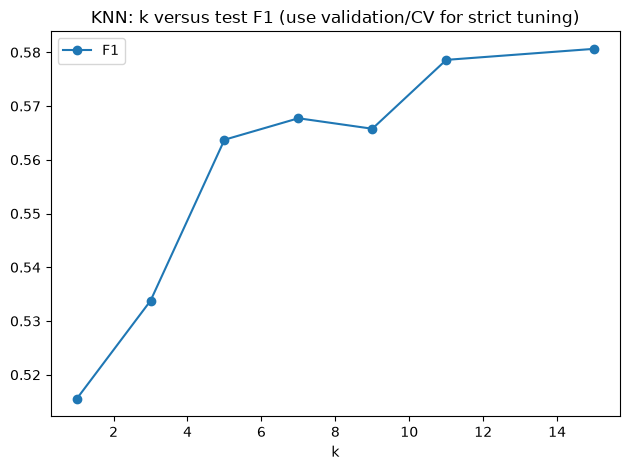

Best k: 15


In [10]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, RocCurveDisplay,
                             classification_report)
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.base import clone

def evaluate_model(name, model, X_eval=X_test_pre, y_eval=y_test):
    pred = model.predict(X_eval)
    proba = model.predict_proba(X_eval)[:, 1] if hasattr(model, "predict_proba") else None
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall": recall_score(y_eval, pred, zero_division=0),
        "F1-Score": f1_score(y_eval, pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_eval, proba) if proba is not None else np.nan,
        "Training Time (seconds)": np.nan
    }

knn_base = KNeighborsClassifier(n_neighbors=5)
t0 = time.perf_counter()
knn_base.fit(X_train_sm, y_train_sm)
knn_time = time.perf_counter() - t0
print("KNN k=5 baseline")
print(classification_report(y_test, knn_base.predict(X_test_pre), target_names=["No churn", "Churn"]))

knn_rows = []
for k in [1, 3, 5, 7, 9, 11, 15]:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_sm, y_train_sm)
    pred = model.predict(X_test_pre)
    knn_rows.append({"k": k, "F1": f1_score(y_test, pred, zero_division=0)})
knn_tuning = pd.DataFrame(knn_rows)
display(knn_tuning)
knn_tuning.plot(x="k", y="F1", marker="o", title="KNN: k versus test F1 (use validation/CV for strict tuning)")
plt.tight_layout()
plt.show()
best_k = int(knn_tuning.sort_values("F1", ascending=False).iloc[0]["k"])
knn_best = KNeighborsClassifier(n_neighbors=best_k)
t0 = time.perf_counter()
knn_best.fit(X_train_sm, y_train_sm)
knn_time = time.perf_counter() - t0
print("Best k:", best_k)

In [11]:
# Gaussian Naive Bayes
nb = GaussianNB()
t0 = time.perf_counter()
nb.fit(X_train_sm, y_train_sm)
nb_time = time.perf_counter() - t0
print("GaussianNB class_prior_:", nb.class_prior_)
print("Training data churn rate before SMOTE:", round(y_train.mean(), 4))
print(classification_report(y_test, nb.predict(X_test_pre), target_names=["No churn", "Churn"]))
print("Independence assumption note: service and billing features can be related, so conditional independence is unlikely to hold perfectly. GaussianNB is still a useful baseline, but correlated features may affect its probability estimates.")

GaussianNB class_prior_: [0.5 0.5]
Training data churn rate before SMOTE: 0.2654
              precision    recall  f1-score   support

    No churn       0.91      0.66      0.77      1035
       Churn       0.47      0.83      0.60       374

    accuracy                           0.71      1409
   macro avg       0.69      0.74      0.68      1409
weighted avg       0.80      0.71      0.72      1409

Independence assumption note: service and billing features can be related, so conditional independence is unlikely to hold perfectly. GaussianNB is still a useful baseline, but correlated features may affect its probability estimates.


## Step 5 — SVM and Decision Tree

              precision    recall  f1-score   support

    No churn       0.89      0.77      0.83      1035
       Churn       0.54      0.73      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409



,C,Mean CV F1
0,0.1,0.778932
1,1.0,0.804375
2,10.0,0.834661
3,100.0,0.828813


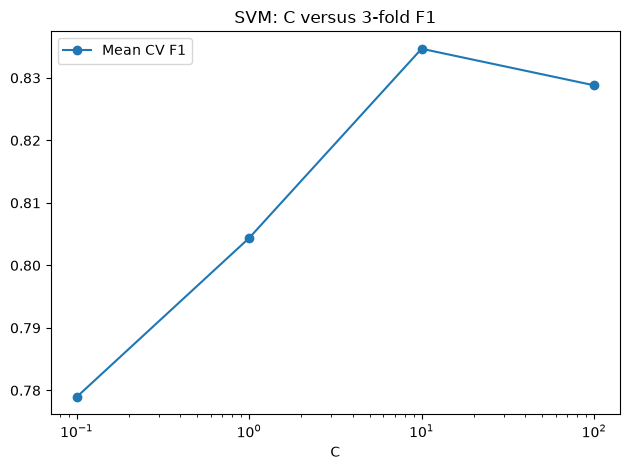

Best C: 10.0


In [12]:
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import cross_val_score

# SVM requested configuration
svm = SVC(kernel="rbf", C=1, gamma="scale", probability=True, random_state=42)
t0 = time.perf_counter()
svm.fit(X_train_sm, y_train_sm)
svm_time = time.perf_counter() - t0
print(classification_report(y_test, svm.predict(X_test_pre), target_names=["No churn", "Churn"]))

# Tune C using 3-fold cross-validation on the already-preprocessed training set.
# For strict leakage-safe CV, preprocessing and SMOTE should be inside an imblearn Pipeline.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
svm_cv_rows = []
for c in [0.1, 1, 10, 100]:
    candidate = SVC(kernel="rbf", C=c, gamma="scale", random_state=42)
    scores = cross_val_score(candidate, X_train_sm, y_train_sm, cv=cv, scoring="f1", n_jobs=-1)
    svm_cv_rows.append({"C": c, "Mean CV F1": scores.mean()})
svm_tuning = pd.DataFrame(svm_cv_rows)
display(svm_tuning)
svm_tuning.plot(x="C", y="Mean CV F1", marker="o", title="SVM: C versus 3-fold F1")
plt.xscale("log")
plt.tight_layout()
plt.show()
best_C = float(svm_tuning.sort_values("Mean CV F1", ascending=False).iloc[0]["C"])
svm_best = SVC(kernel="rbf", C=best_C, gamma="scale", probability=True, random_state=42)
t0 = time.perf_counter()
svm_best.fit(X_train_sm, y_train_sm)
svm_time = time.perf_counter() - t0
print("Best C:", best_C)

              precision    recall  f1-score   support

    No churn       0.90      0.75      0.82      1035
       Churn       0.52      0.76      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



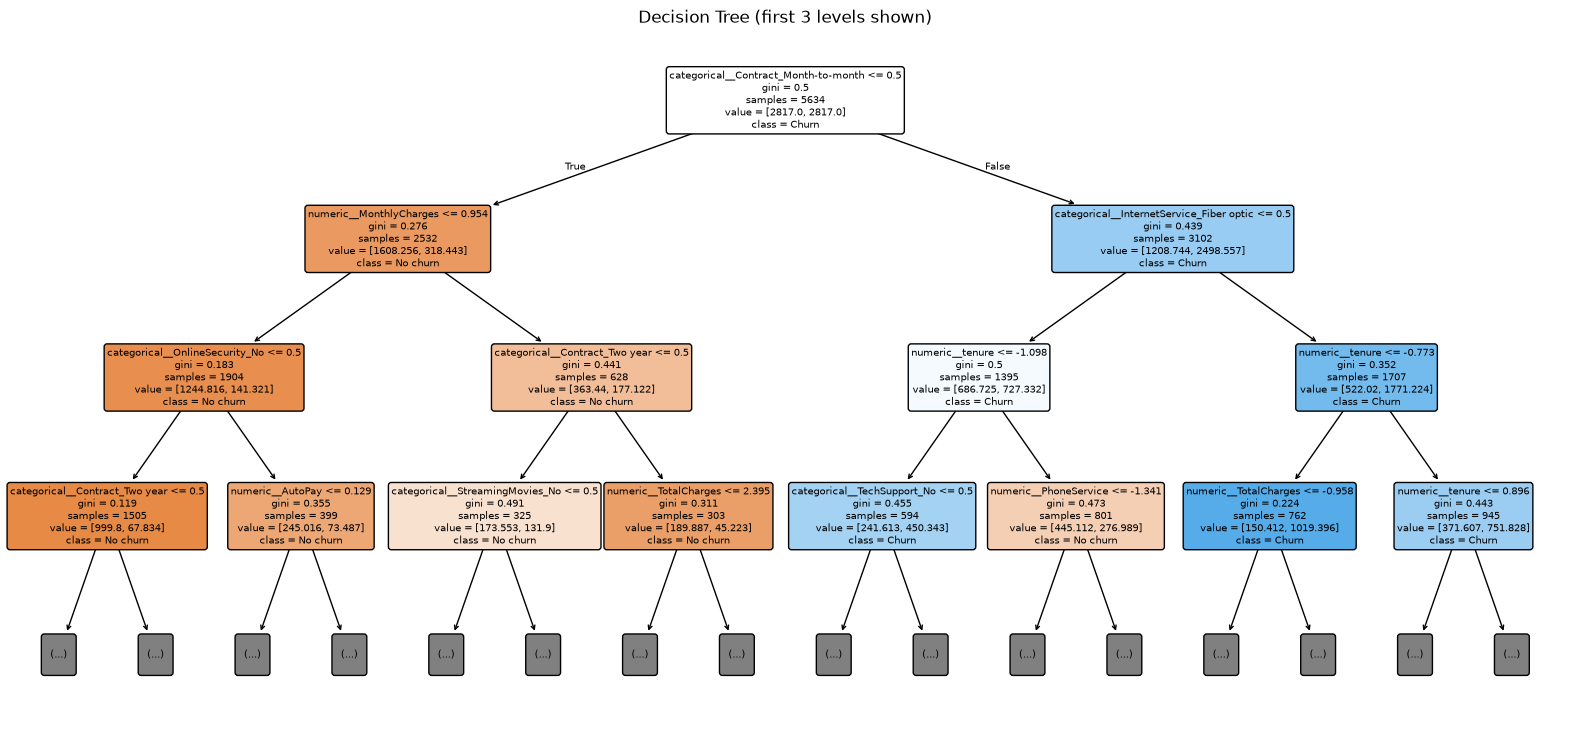

,max_depth,Mean CV F1
0,3,0.606572
1,4,0.612439
2,5,0.616720
3,6,0.604309
4,7,0.599390
5,8,0.590177
6,None,0.488866


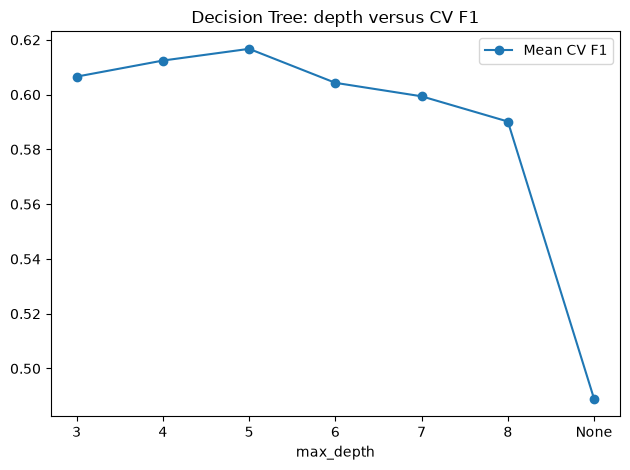

Best depth: 5


In [13]:
# Decision Tree baseline and depth tuning
tree = DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42)
t0 = time.perf_counter()
tree.fit(X_train_pre, y_train)  # class_weight comparison uses original training data
tree_time = time.perf_counter() - t0
print(classification_report(y_test, tree.predict(X_test_pre), target_names=["No churn", "Churn"]))

plt.figure(figsize=(20, 9))
plot_tree(tree, feature_names=feature_names, class_names=["No churn", "Churn"],
          max_depth=3, filled=True, rounded=True, fontsize=7)
plt.title("Decision Tree (first 3 levels shown)")
plt.show()

depth_rows = []
for depth in [3, 4, 5, 6, 7, 8, None]:
    candidate = DecisionTreeClassifier(max_depth=depth, class_weight="balanced", random_state=42)
    scores = cross_val_score(candidate, X_train_pre, y_train, cv=cv, scoring="f1", n_jobs=-1)
    depth_rows.append({"max_depth": str(depth), "Mean CV F1": scores.mean()})
depth_tuning = pd.DataFrame(depth_rows)
display(depth_tuning)
depth_tuning.plot(x="max_depth", y="Mean CV F1", marker="o", title="Decision Tree: depth versus CV F1")
plt.tight_layout()
plt.show()
best_depth_text = depth_tuning.sort_values("Mean CV F1", ascending=False).iloc[0]["max_depth"]
best_depth = None if best_depth_text == "None" else int(best_depth_text)
tree_best = DecisionTreeClassifier(max_depth=best_depth, class_weight="balanced", random_state=42)
t0 = time.perf_counter()
tree_best.fit(X_train_pre, y_train)
tree_time = time.perf_counter() - t0
print("Best depth:", best_depth)

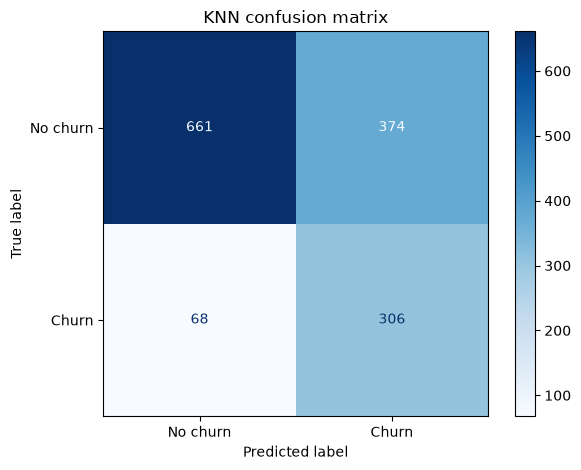

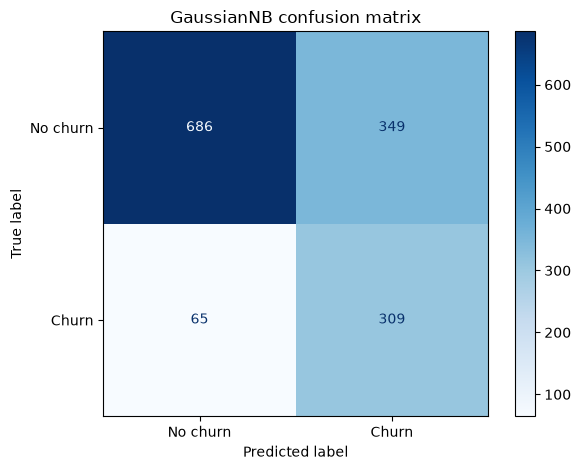

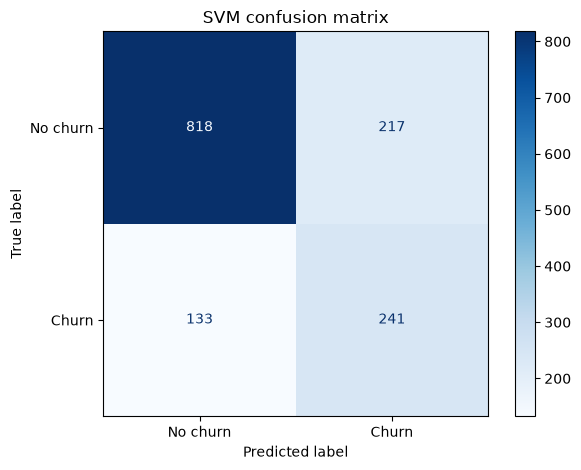

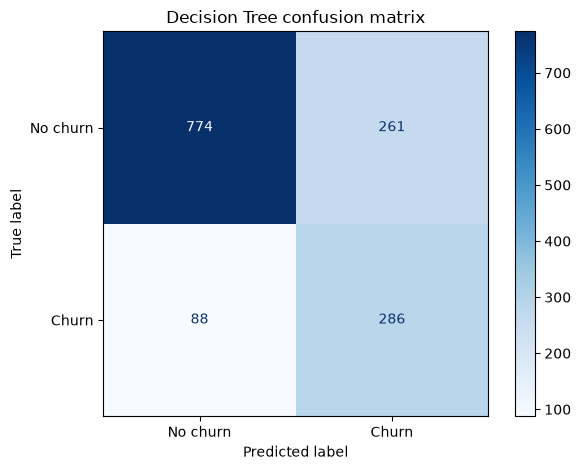

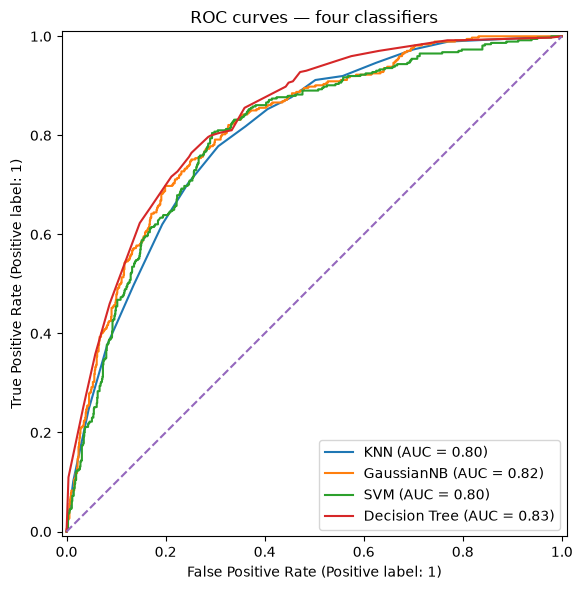

In [14]:
# Confusion matrix helper and ROC plots
from sklearn.metrics import ConfusionMatrixDisplay
models = {
    "KNN": (knn_best, X_train_sm, y_train_sm, knn_time),
    "GaussianNB": (nb, X_train_sm, y_train_sm, nb_time),
    "SVM": (svm_best, X_train_sm, y_train_sm, svm_time),
    "Decision Tree": (tree_best, X_train_pre, y_train, tree_time)
}

for name, (model, _, _, _) in models.items():
    pred = model.predict(X_test_pre)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["No churn", "Churn"], cmap="Blues")
    plt.title(f"{name} confusion matrix")
    plt.tight_layout()
    plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
for name, (model, _, _, _) in models.items():
    RocCurveDisplay.from_estimator(model, X_test_pre, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
ax.set_title("ROC curves — four classifiers")
plt.tight_layout()
plt.show()

## Step 6 — Compare all models and choose a business-ready option

,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Training Time (seconds)
0,GaussianNB,0.7062,0.4696,0.8262,0.5988,0.8153,0.0239
1,KNN,0.6863,0.4500,0.8182,0.5806,0.8020,0.0048
2,Decision Tree,0.7523,0.5229,0.7647,0.6211,0.8329,0.0502
3,SVM,0.7516,0.5262,0.6444,0.5793,0.8008,46.7915


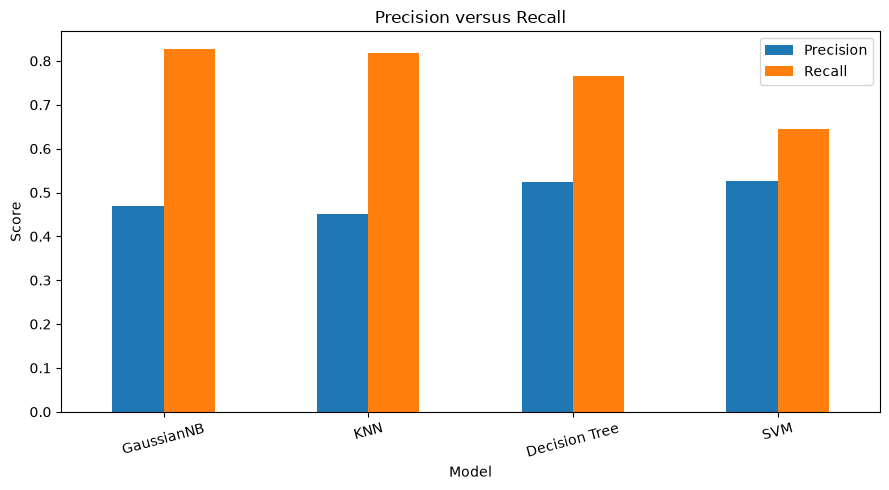

Recommendation guide: choose a model with strong churn recall, acceptable precision, reasonable latency, and enough interpretability for the retention team. Use the comparison table above as the evidence; do not claim a winner before checking the measured metrics.


In [15]:
results = []
for name, (model, _, _, fit_time) in models.items():
    pred = model.predict(X_test_pre)
    proba = model.predict_proba(X_test_pre)[:, 1] if hasattr(model, "predict_proba") else None
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-Score": f1_score(y_test, pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_test, proba) if proba is not None else np.nan,
        "Training Time (seconds)": fit_time
    })
comparison = pd.DataFrame(results).sort_values("Recall", ascending=False).reset_index(drop=True)
display(comparison.round(4))
comparison.to_csv("outputs/model_comparison.csv", index=False)

comparison.set_index("Model")[["Precision", "Recall"]].plot(kind="bar", figsize=(9, 5), title="Precision versus Recall")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print("Recommendation guide: choose a model with strong churn recall, acceptable precision, reasonable latency, and enough interpretability for the retention team. Use the comparison table above as the evidence; do not claim a winner before checking the measured metrics.")

## Step 7 — Error analysis and interpretation

False negatives: 65


,tenure,MonthlyCharges,Contract
count,65.000000,65.000000,65
unique,NaN,NaN,3
top,NaN,NaN,One year
freq,NaN,NaN,29
mean,32.753846,63.423846,NaN
std,26.122327,37.956078,NaN
min,1.000000,18.950000,NaN
25%,3.000000,20.200000,NaN
50%,35.000000,67.500000,NaN
75%,57.000000,100.450000,NaN


Missed churners by contract:


Contract
One year          44.62
Month-to-month    41.54
Two year          13.85
Name: proportion, dtype: float64

categorical__Contract_Month-to-month        0.607969
numeric__tenure                             0.115471
categorical__InternetService_Fiber optic    0.107911
numeric__MonthlyCharges                     0.047272
categorical__TechSupport_No                 0.021184
numeric__TotalCharges                       0.021152
categorical__Contract_Two year              0.017037
numeric__AutoPay                            0.013991
categorical__OnlineSecurity_No              0.012708
numeric__PhoneService                       0.011624
numeric__num_services                       0.005698
numeric__Dependents                         0.005568
categorical__StreamingTV_No                 0.004643
categorical__StreamingMovies_No             0.003941
categorical__TechSupport_Yes                0.003413
Name: Importance, dtype: float64

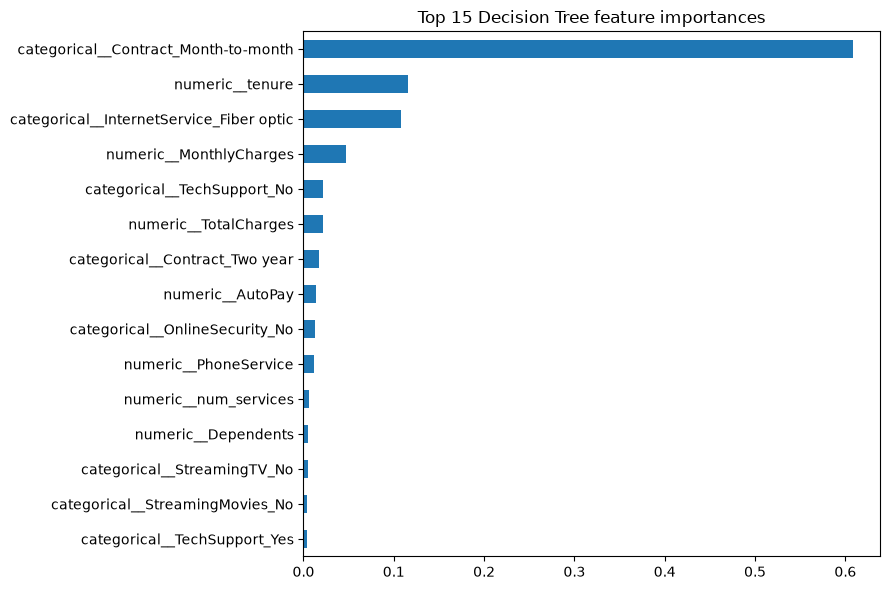

In [16]:
# Choose the highest-recall model from the measured comparison.
best_name = comparison.iloc[0]["Model"]
best_model = models[best_name][0]
test_predictions = best_model.predict(X_test_pre)

# False negatives: actual churn = 1, predicted no churn = 0.
fn_mask = (y_test.to_numpy() == 1) & (test_predictions == 0)
X_test_original = X_test.loc[y_test.index].copy()
false_negatives = X_test_original.loc[fn_mask].copy()
print("False negatives:", len(false_negatives))
if len(false_negatives):
    display(false_negatives[["tenure", "MonthlyCharges", "Contract"]].describe(include="all"))
    print("Missed churners by contract:")
    display(false_negatives["Contract"].value_counts(normalize=True).mul(100).round(2))
else:
    print("No false negatives on this test split.")

# Decision Tree feature importance
tree_importance = pd.Series(tree_best.feature_importances_, index=feature_names).sort_values(ascending=False)
display(tree_importance.head(15).rename("Importance"))
tree_importance.head(15).sort_values().plot(kind="barh", figsize=(9, 6), title="Top 15 Decision Tree feature importances")
plt.tight_layout()
plt.show()

## Step 8 — Save a reusable prediction pipeline

The saved artifact accepts **raw customer columns** (excluding `customerID` and `Churn`), creates the engineered features, applies imputation/encoding/scaling, and predicts churn. The deployment pipeline uses SMOTE only while fitting; `predict` and `predict_proba` transform the incoming customers normally.

In [22]:
# Repeatable feature engineering for new raw records
def feature_engineering_for_pipeline(frame):
    return add_features(frame)

# Build column lists from the engineered training data
raw_X = df.drop(columns=["Churn", "customerID", "tenure_bucket"], errors="ignore").copy()
engineered = add_features(raw_X)
num_cols = engineered.select_dtypes(include=["number"]).columns.tolist()
cat_cols = engineered.select_dtypes(exclude=["number"]).columns.tolist()

deployment_preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

final_pipeline = ImbPipeline([
    ("features", FunctionTransformer(feature_engineering_for_pipeline, validate=False)),
    ("preprocessor", deployment_preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("model", clone(best_model))
])

# FIXED: two separate lines
raw_train_for_deploy = X_raw.loc[X_train.index].copy()
final_pipeline.fit(raw_train_for_deploy, y_train)

joblib.dump(final_pipeline, "churn_model.pkl")
print("Saved churn_model.pkl using:", best_name)

# Reload and test five sample customers
loaded_pipeline = joblib.load("churn_model.pkl")
samples = X_raw.loc[X_test.index].head(5).copy()
probabilities = loaded_pipeline.predict_proba(samples)[:, 1]
labels = loaded_pipeline.predict(samples)

sample_output = pd.DataFrame({
    "Predicted_Churn_Probability": probabilities.round(4),
    "Predicted_Label": np.where(labels == 1, "Yes", "No")
}, index=samples.index)

display(sample_output)

os.makedirs("outputs", exist_ok=True)
sample_output.to_csv("outputs/sample_predictions.csv", index=True)

Saved churn_model.pkl using: GaussianNB


,Predicted_Churn_Probability,Predicted_Label
437,0.0000,No
2280,1.0000,Yes
2235,0.0000,No
4460,0.9999,Yes
3761,0.0000,No
